In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.utils import to_categorical

In [26]:
import pandas as pd

df = pd.read_csv("sign_mnist_train.csv")
print(df.shape)
print(df.head())

(27455, 785)
   label  pixel1  pixel2  pixel3  pixel4  pixel5  pixel6  pixel7  pixel8  \
0      3     107     118     127     134     139     143     146     150   
1      6     155     157     156     156     156     157     156     158   
2      2     187     188     188     187     187     186     187     188   
3      2     211     211     212     212     211     210     211     210   
4     13     164     167     170     172     176     179     180     184   

   pixel9  ...  pixel775  pixel776  pixel777  pixel778  pixel779  pixel780  \
0     153  ...       207       207       207       207       206       206   
1     158  ...        69       149       128        87        94       163   
2     187  ...       202       201       200       199       198       199   
3     210  ...       235       234       233       231       230       226   
4     185  ...        92       105       105       108       133       163   

   pixel781  pixel782  pixel783  pixel784  
0       206      

In [27]:
X = df.drop("label", axis=1).values
y = df["label"].values

X = X.reshape(-1, 28, 28, 1)
X = X / 255.0

In [28]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [29]:
from tensorflow.keras.utils import to_categorical

y_train = to_categorical(y_train, num_classes=25)
y_test = to_categorical(y_test, num_classes=25)

In [33]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

model = Sequential([
    Conv2D(32, (3,3), activation="relu", input_shape=(28,28,1)),
    MaxPooling2D((2,2)),
    Conv2D(64, (3,3), activation="relu"),
    MaxPooling2D((2,2)),
    Flatten(),
    Dense(64, activation="relu"),
    Dense(25, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)              │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 25)             │         1,625 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,905 (480.10 KB)

 Trainable params: 122,905 (480.10 KB)

 Non-trainable params: 0 (0.00 B)

In [31]:
print(X_train.shape)
print(y_train.shape)
print(np.unique(y_train))

(21964, 28, 28, 1)
(21964, 25)
[0. 1.]


In [34]:
history = model.fit(
    X_train,
    y_train,
    epochs=5,
    validation_split=0.2,
    batch_size=32
)

Epoch 1/5
550/550 ━━━━━━━━━━━━━━━━━━━━ 20s 34ms/step - accuracy: 0.5678 - loss: 1.4555 - val_accuracy: 0.8539 - val_loss: 0.4609
Epoch 2/5
550/550 ━━━━━━━━━━━━━━━━━━━━ 19s 35ms/step - accuracy: 0.9363 - loss: 0.2352 - val_accuracy: 0.9763 - val_loss: 0.1024
Epoch 3/5
550/550 ━━━━━━━━━━━━━━━━━━━━ 20s 37ms/step - accuracy: 0.9902 - loss: 0.0563 - val_accuracy: 0.9877 - val_loss: 0.0537
Epoch 4/5
550/550 ━━━━━━━━━━━━━━━━━━━━ 19s 35ms/step - accuracy: 0.9989 - loss: 0.0156 - val_accuracy: 0.9998 - val_loss: 0.0077
Epoch 5/5
550/550 ━━━━━━━━━━━━━━━━━━━━ 20s 37ms/step - accuracy: 0.9946 - loss: 0.0212 - val_accuracy: 0.9989 - val_loss: 0.0128


In [35]:
test_loss, test_acc = model.evaluate(X_test, y_test)

print("Test Accuracy:", test_acc)
print("Test Loss:", test_loss)

172/172 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9985 - loss: 0.0131
Test Accuracy: 0.9985430836677551
Test Loss: 0.013125159777700901


In [36]:
predictions = model.predict(X_test)

172/172 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step


In [38]:
import numpy as np

predicted_label = np.argmax(predictions[0])
actual_label = np.argmax(y_test[0])

print("Predicted:", predicted_label)
print("Actual:", actual_label)

Predicted: 24
Actual: 24


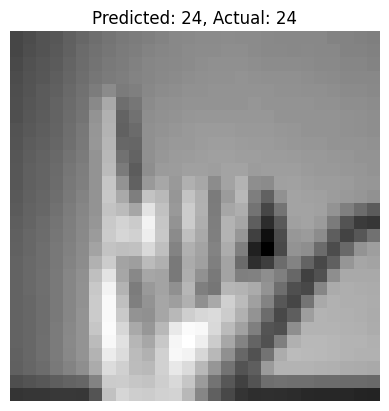

In [39]:
import matplotlib.pyplot as plt

plt.imshow(X_test[0].reshape(28,28), cmap="gray")
plt.title(f"Predicted: {predicted_label}, Actual: {actual_label}")
plt.axis("off")
plt.show()